<a href="https://colab.research.google.com/github/HannaSkrypnyk/DTA-Python-26/blob/main/Hanna_Pandas6_lesson_30_10_26_dates_plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐼📈 Pandas і графіки для аналітиків · Блокнот 6 з 7
## Робота з датами · 📈 Графіки динаміки

Майже кожен бізнес-показник прив'язаний до часу: продажі **по місяцях**, «у вихідні купують більше?», «скільки днів іде доставка?», «як змінилася виручка порівняно з минулим місяцем?».

### У цьому блокноті ви навчитеся
1. Перетворювати текст на **справжні дати**.
2. Діставати з дати рік, місяць, день тижня.
3. Фільтрувати за періодом.
4. Рахувати **різницю між датами** (наприклад, час доставки).
5. Групувати за часом і будувати **графік динаміки**.
6. Згладжувати «шум» **ковзним середнім**.
7. 📈 Підписувати місяці на осі **назвами** замість номерів.
8. 📈 Ставити **стрілку з підписом** на важливу точку і **затінювати період**.
9. 📈 Порівнювати кілька рядів: кілька ліній і **«малі мультиплікатори»** (сітка маленьких графіків).
10. 📈 Будувати теплову карту «день тижня × місяць».

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

01. Знайомство з pandas · 📈 Перший графік<br>02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка<br>03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних<br>04. Групування та зведені таблиці · 📈 Графіки з групувань<br>05. Об'єднання таблиць · 📈 Порівняння і зв'язки<br>**06. Робота з датами · 📈 Графіки динаміки** ← ви тут<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Готуємо дані

In [2]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",         "Electronics", 1500,  900),
    ("P02", "Power bank",         "Electronics",  900,  520),
    ("P03", "Smartwatch",    "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",          "Clothing",         450,  180),
    ("P06", "Hoodie",              "Clothing",        1200,  550),
    ("P07", "Jeans",            "Clothing",        1600,  800),
    ("P08", "Sneakers",          "Clothing",        2800, 1600),
    ("P09", "Mug",             "Home",          180,   60),
    ("P10", "Blanket",              "Home",          850,  400),
    ("P11", "Desk lamp",   "Home",         1100,  600),
    ("P12", "Towel set",    "Home",          650,  300),
    ("P13", "Face cream",  "Beauty",        520,  210),
    ("P14", "Shampoo",           "Beauty",        260,  110),
    ("P15", "Perfume",           "Beauty",       2400, 1300),
    ("P16", "Yoga mat",  "Sports",        700,  320),
    ("P17", "Water bottle",   "Sports",        350,  140),
    ("P18", "Dumbbells 5 kg",      "Sports",        950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Одна велика таблиця продажів ----------
sales = (orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
               .merge(products[["product_id", "product", "category", "price"]], on="product_id", how="left"))
sales = sales[["order_id", "order_date", "delivery_date", "customer_id", "city", "category",
               "product", "price", "quantity", "payment", "channel", "status", "rating"]]
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
for q in range(1, 5):
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
raw = sales.copy()
raw["price"] = raw["price"].astype(str) + " UAH"
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime("%d.%m.%Y")
messy = {"Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"], "Lviv": ["lviv", "Lviv ", " LVIV"],
         "Odesa": ["odesa", "Odesa "], "Kharkiv": ["kharkiv", "KHARKIV "], "Dnipro": ["dnipro", " Dnipro"]}
city_col = raw["city"].to_numpy(dtype=object)
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])
city_col[rng.choice(n, 15, replace=False)] = None
raw["city"] = city_col
qty_col = raw["quantity"].to_numpy(dtype=float)
qty_col[rng.choice(n, 40, replace=False)] = np.nan
raw["quantity"] = qty_col
pay_col = raw["payment"].to_numpy(dtype=object)
pay_col[rng.choice(n, 60, replace=False)] = None
raw["payment"] = pay_col
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)
raw.columns = ["Order ID", "Order Date", "Delivery Date", "Customer ID", "City", "Category",
               "Product", "Price", "Qty", "Payment", "Channel", "Status", "Rating"]

# ---------- «Брудний» список клієнтів ----------
craw = customers.copy()
name_col = craw["name"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice([name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "])
craw["name"] = name_col
cc = craw["city"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])
craw["city"] = cc
age_col = craw["age"].to_numpy(dtype=float)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan
craw["age"] = age_col
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime("%d/%m/%Y")
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)

# ---------- Зберігаємо файли ----------
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків (з блокнота 2) ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, quarter, q, raw, messy, city_col, qty_col, pay_col, craw, name_col, cc, age_col, i,
     sales, orders, customers, products)

print("✅ Done! Data files created:")
print("   sales.csv, orders.csv, customers.csv, products.csv,")
print("   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv")

✅ Done! Data files created:
   sales.csv, orders.csv, customers.csv, products.csv,
   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")
df["revenue"] = df["price"] * df["quantity"]

---
## Крок 1. Текст → дата

Подивимося, який тип мають стовпці з датами після читання файлу:

In [1]:
df[["order_date", "delivery_date"]].dtypes

NameError: name 'df' is not defined

Це **текст** (`object` або `str`). З текстом не вийде дізнатися місяць чи порахувати, скільки днів минуло. Перетворюємо через `pd.to_datetime()`:

In [4]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["delivery_date"] = pd.to_datetime(df["delivery_date"])

df[["order_date", "delivery_date"]].dtypes

,0
order_date,datetime64[ns]
delivery_date,datetime64[ns]


Тепер тип **`datetime64`**: справжня дата. Наш формат `2025-03-14` (рік-місяць-день) — міжнародний стандарт, тому `format` вказувати не потрібно. Для інших форматів (`14.03.2025`) пам'ятаєте `format="%d.%m.%Y"` з блокнота 3.

💡 **Швидший спосіб:** перетворити дати одразу під час читання файлу. Для цього є параметр `parse_dates`, наприклад: `df = pd.read_csv("sales.csv", parse_dates=["order_date", "delivery_date"])`.

---
## Крок 2. Частини дати: `.dt`

Як `.str` дає доступ до текстових команд, так **`.dt`** дає доступ до команд для дат:

| Команда | Що повертає | Приклад для 2025-11-28 |
|---|---|---|
| `.dt.year` | рік | 2025 |
| `.dt.month` | номер місяця | 11 |
| `.dt.day` | день місяця | 28 |
| `.dt.quarter` | квартал | 4 |
| `.dt.dayofweek` | день тижня: **0 = понеділок**, 6 = неділя | 4 |
| `.dt.to_period("M")` | місяць як період | 2025-11 |

In [5]:
df["month"] = df["order_date"].dt.month
df["quarter"] = df["order_date"].dt.quarter
df["weekday"] = df["order_date"].dt.dayofweek

df[["order_date", "month", "quarter", "weekday"]].head()

,order_date,month,quarter,weekday
0,2025-01-01,1,1,2
1,2025-01-01,1,1,2
2,2025-01-01,1,1,2
3,2025-01-01,1,1,2
4,2025-01-01,1,1,2


Номер дня тижня незручно читати. Перетворимо його на назву через `map` зі словником (блокнот 3):

In [6]:
weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}

df["weekday_name"] = df["weekday"].map(weekday_names)
df[["order_date", "weekday", "weekday_name"]].head()

,order_date,weekday,weekday_name
0,2025-01-01,2,Wed
1,2025-01-01,2,Wed
2,2025-01-01,2,Wed
3,2025-01-01,2,Wed
4,2025-01-01,2,Wed


---
## Крок 3. Фільтр за періодом

Справжні дати можна порівнювати з текстом у форматі `"рік-місяць-день"`:

In [7]:
summer = df[(df["order_date"] >= "2025-06-01") & (df["order_date"] <= "2025-08-31")]
print("Orders in summer:", len(summer))

november = df[df["order_date"].between("2025-11-01", "2025-11-30")]
print("Orders in November:", len(november))

december = df[df["order_date"].dt.month == 12]          # через номер місяця
print("Orders in December:", len(december))

weekend = df[df["weekday"] >= 5]                        # субота й неділя
print("Orders on weekends:", len(weekend))

Orders in summer: 636
Orders in November: 478
Orders in December: 394
Orders on weekends: 999


---
## Крок 4. Різниця між датами

Якщо відняти одну дату від іншої, отримаємо **проміжок часу**. `.dt.days` перетворює його на кількість днів:

In [8]:
df["delivery_days"] = (df["delivery_date"] - df["order_date"]).dt.days

df[["order_date", "delivery_date", "delivery_days"]].head()

,order_date,delivery_date,delivery_days
0,2025-01-01,NaT,NaN
1,2025-01-01,2025-01-02,1.00
2,2025-01-01,2025-01-05,4.00
3,2025-01-01,2025-01-02,1.00
4,2025-01-01,2025-01-06,5.00


💡 Дні показані як `1.00`, бо в стовпці є пропуски (`NaN`) для скасованих замовлень. У стовпці з цілими числами пропусків бути не може, тому pandas робить його дробовим. Пам'ятаєте `rating` з блокнота 1?

In [9]:
print("Average delivery time:", df["delivery_days"].mean().round(1), "days")

df.groupby("city")["delivery_days"].mean().round(1).sort_values()

Average delivery time: 2.5 days


,delivery_days
city,
Kyiv,1.50
Kharkiv,2.80
Lviv,3.00
Odesa,3.00
Dnipro,3.10


Для скасованих замовлень дати доставки немає, тому й `delivery_days` порожній. Середнє рахується лише по доставлених, як і має бути.

Можна також додавати дні до дати через `pd.Timedelta`:

In [10]:
# Дата, до якої клієнт може повернути товар: 14 днів після доставки
df["return_deadline"] = df["delivery_date"] + pd.Timedelta(days=14)

df[["delivery_date", "return_deadline"]].head(3)

,delivery_date,return_deadline
0,NaT,NaT
1,2025-01-02,2025-01-16
2,2025-01-05,2025-01-19


---
## Крок 5. Динаміка по місяцях

Групуємо за місяцем. `dt.to_period("M")` перетворює дату на «рік-місяць», тому навіть дані за кілька років не змішаються.

In [11]:
monthly = df.groupby(df["order_date"].dt.to_period("M"))["revenue"].sum()
monthly

,revenue
order_date,
2025-01,257410
2025-02,195560
2025-03,211420
2025-04,297690
2025-05,297010
2025-06,268280
2025-07,253560
2025-08,291740
2025-09,330540


Для динаміки найкраще підходить **лінійний графік** (`.plot()` без параметрів):

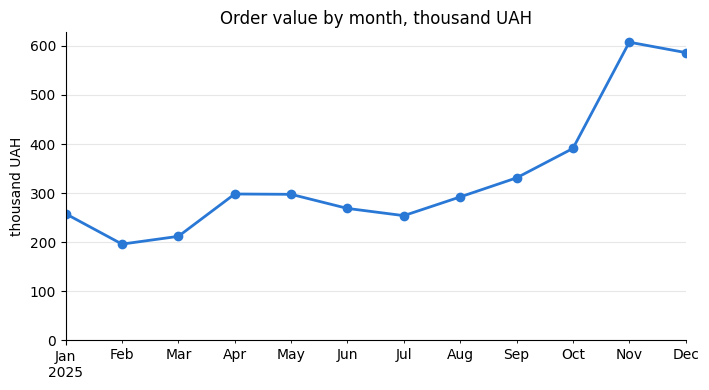

In [12]:
(monthly / 1000).plot(marker="o")
plt.title("Order value by month, thousand UAH")
plt.xlabel("")
plt.ylabel("thousand UAH")
plt.ylim(bottom=0)        # вісь від нуля, щоб не перебільшувати коливання
plt.show()

**Що видно:** найнижчі продажі в лютому й березні, навесні ріст, улітку невеликий спад, з вересня знову ріст, а в листопаді різкий стрибок. Перевіримо, звідки цей стрибок.

### Зміна до попереднього місяця: `pct_change()`
`pct_change()` рахує, на скільки відсотків кожне значення відрізняється від попереднього:

In [13]:
(monthly.pct_change() * 100).round(1)

,revenue
order_date,
2025-01,NaN
2025-02,-24.00
2025-03,8.10
2025-04,40.80
2025-05,-0.20
2025-06,-9.70
2025-07,-5.50
2025-08,15.10
2025-09,13.30


Перший місяць має `NaN`, бо порівнювати його нема з чим.

### Рекордний день
Знайдемо день з найбільшою сумою замовлень:

In [14]:
daily = df.groupby("order_date")["revenue"].sum()

print("Record day:", daily.idxmax().date())
print("Order value that day:", daily.max(), "UAH")
print("Typical day (median):", daily.median(), "UAH")

Record day: 2025-11-28
Order value that day: 93930 UAH
Typical day (median): 9090.0 UAH


**28 листопада 2025 — це Чорна п'ятниця.** За один день замовили на 94 тис. грн, тоді як звичайний день дає близько 9 тис. Це частина пояснення листопадового стрибка, решту дає загальний передсвятковий сезон.

### 📈 Підписуємо важливу точку: `plt.annotate`
Читач не мусить сам здогадуватися, що це за пік. Підпишемо його стрілкою:
- `xy` — **куди** вказує стрілка (дата і значення піку);
- `xytext` — **де** стоїть текст (тут: на 120 днів раніше і трохи нижче);
- `arrowprops` — вигляд стрілки.

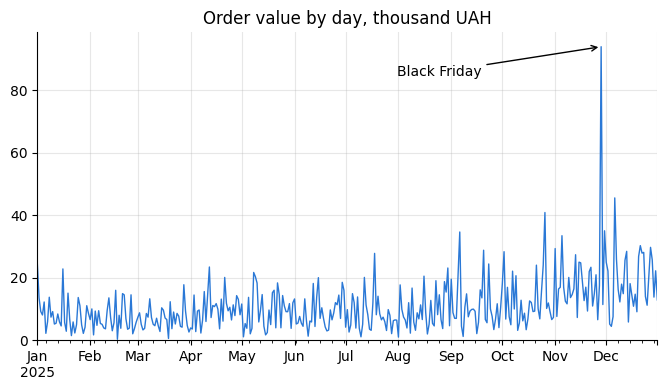

In [15]:
(daily / 1000).plot(linewidth=1)

peak_day = daily.idxmax()
peak_value = daily.max() / 1000
plt.annotate(
    "Black Friday",
    xy=(peak_day, peak_value),
    xytext=(peak_day - pd.Timedelta(days=120), peak_value * 0.9),
    arrowprops=dict(arrowstyle="->"),
)
plt.title("Order value by day, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

### 📈 Назви місяців замість номерів
Часто зручно групувати за **номером** місяця (стовпець `month`): так ми робитимемо далі для кількох ліній і теплової карти. Але тоді на осі будуть просто числа. Замінимо номери на короткі назви (Jan, Feb, …), як ми вже робили з днями тижня.

💡 Номера місяця досить, бо в нас дані за один рік. Якщо років кілька, групуйте за `dt.to_period("M")`, інакше січні різних років зіллються в один.

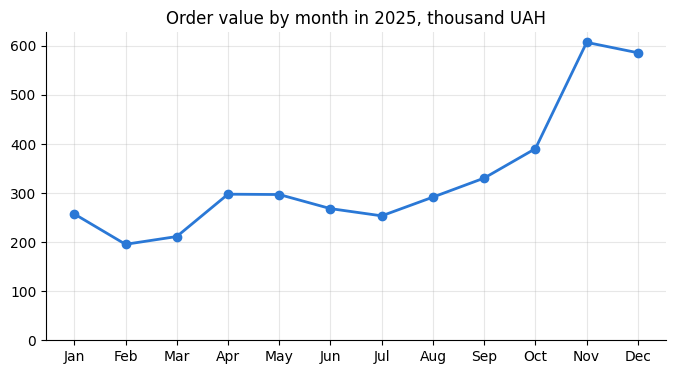

In [16]:
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

by_month = df.groupby("month")["revenue"].sum() / 1000
by_month.index = by_month.index.map(month_names)

by_month.plot(marker="o")
plt.xticks(range(12), by_month.index)        # показати підпис під кожною точкою
plt.title("Order value by month in 2025, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

💡 Без `plt.xticks(...)` matplotlib показав би підпис лише під кожним другим місяцем. `plt.xticks(позиції, підписи)` явно каже: «під точками 0, 1, …, 11 напиши ці назви».

---
## Крок 6. Коли купують: дні тижня

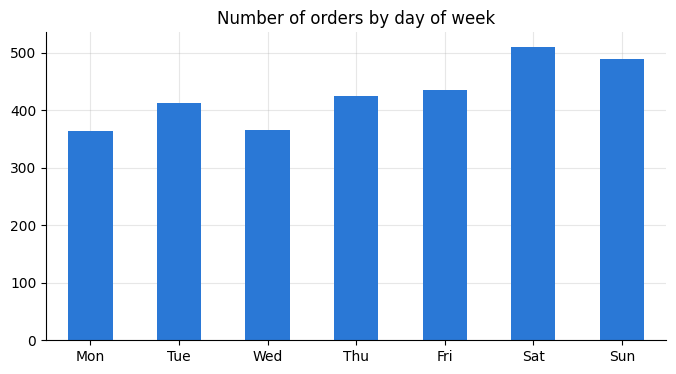

In [17]:
by_weekday = df.groupby("weekday")["order_id"].count()
by_weekday.index = by_weekday.index.map(weekday_names)     # 0..6 → Mon..Sun, порядок зберігається

by_weekday.plot(kind="bar", rot=0)
plt.title("Number of orders by day of week")
plt.xlabel("")
plt.show()

💡 Ми групували за **номером** дня (0–6), а назви підставили потім. Так дні йдуть у правильному порядку. Якщо групувати одразу за назвою, pandas відсортує їх за алфавітом: Fri, Mon, Sat…

## Крок 7. Тижні та `resample`

Ще один спосіб групувати за часом — **`resample`**. Йому потрібно вказати стовпець з датою (`on=`) і період:

| Період | Значення |
|---|---|
| `"D"` | день |
| `"W"` | тиждень |
| `"MS"` | місяць (з першого числа) |
| `"QS"` | квартал |

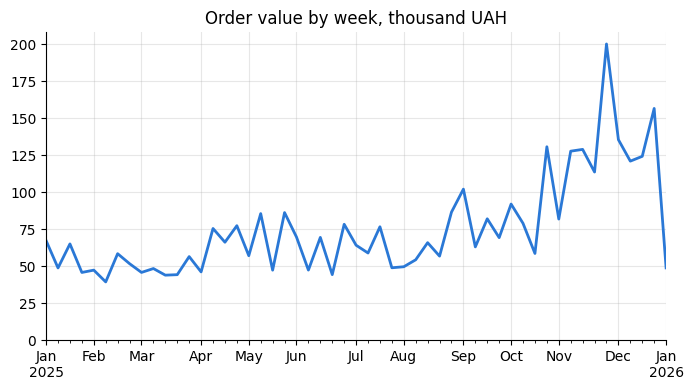

In [18]:
weekly = df.resample("W", on="order_date")["revenue"].sum()

(weekly / 1000).plot()
plt.title("Order value by week, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

⚠️ **Пастка неповного періоду.** Наприкінці лінія різко падає. Це не обвал продажів: останній «тиждень» містить лише 3 дні, 29–31 грудня (тижні в pandas закінчуються в неділю, а 2026 рік ми не бачимо). Перш ніж робити висновки про останній тиждень чи місяць, перевіряйте, чи він повний.

---
## Крок 8. Ковзне середнє: прибираємо «шум»

Щоденні продажі сильно «стрибають», і за цими стрибками важко побачити загальну тенденцію. **Ковзне середнє за 7 днів** — це середнє за останній тиждень, пораховане для кожного дня. Воно згладжує коливання.

`.rolling(7).mean()` = «для кожного дня візьми 7 останніх значень і порахуй середнє».

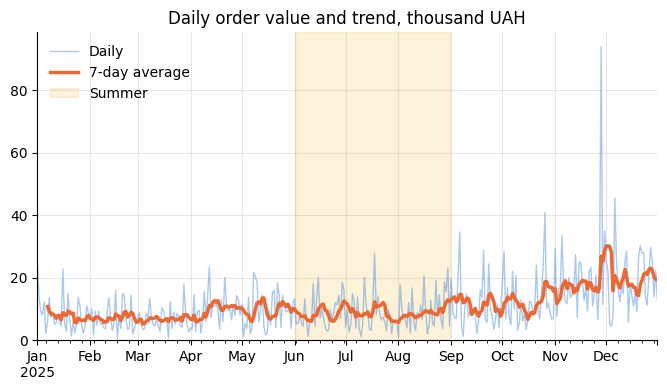

In [19]:
daily_k = df.resample("D", on="order_date")["revenue"].sum() / 1000
trend_k = daily_k.rolling(7).mean()

ax = daily_k.plot(linewidth=1, alpha=0.4, label="Daily")        # alpha — прозорість лінії
trend_k.plot(ax=ax, linewidth=2.5, label="7-day average")      # ax=ax — малюємо на тому ж графіку
plt.axvspan(pd.Timestamp("2025-06-01"), pd.Timestamp("2025-08-31"),
            color="#eda100", alpha=0.15, label="Summer")                # затінений період
plt.title("Daily order value and trend, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend()
plt.show()

Світла лінія «шумить», а яскрава чітко показує: навесні ріст, улітку невеликий спад, з вересня знову ріст, у листопаді пік розпродажів.

💡 Перші 6 днів ковзного середнього порожні: для них ще немає 7 попередніх значень.

📈 `plt.axvspan(початок, кінець)` затінює період на графіку. Так зручно показувати акції, сезони, час запуску реклами. `alpha=0.15` робить заливку ледь помітною, щоб вона не перекривала лінії.

---
## 📈 Крок 9. Кілька рядів даних

### Кілька ліній на одному графіку
Як змінювалася виручка **кожної категорії** по місяцях? Зведена таблиця (рядки — місяці, стовпці — категорії) малюється як кілька ліній:

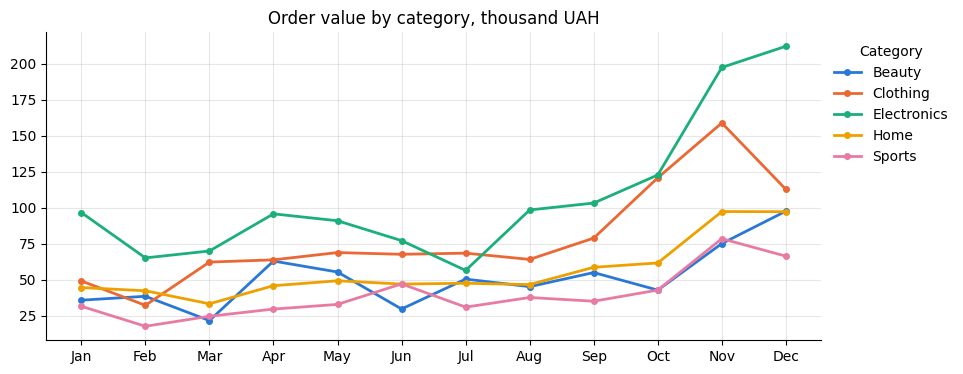

In [20]:
cat_month = pd.pivot_table(df, index="month", columns="category", values="revenue", aggfunc="sum") / 1000
cat_month.index = cat_month.index.map(month_names)

cat_month.plot(marker="o", markersize=4, figsize=(10, 4))
plt.xticks(range(12), cat_month.index)
plt.title("Order value by category, thousand UAH")
plt.xlabel("")
plt.legend(title="Category", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

П'ять ліній уже переплітаються, і стежити за кожною важко. Такий графік жартома називають «спагеті».

### 📈 «Малі мультиплікатори»: сітка маленьких графіків
Рішення: окремий маленький графік для кожної категорії, **з однаковою шкалою**. Тоді форму кожної лінії видно чітко, а висоти можна порівнювати.

- `subplots=True` — кожен стовпець таблиці на окремому графіку;
- `layout=(2, 3)` — сітка 2 рядки × 3 стовпці;
- `sharey=True` — однакова вертикальна шкала для всіх;
- `title=[...]` — заголовок кожного маленького графіка.

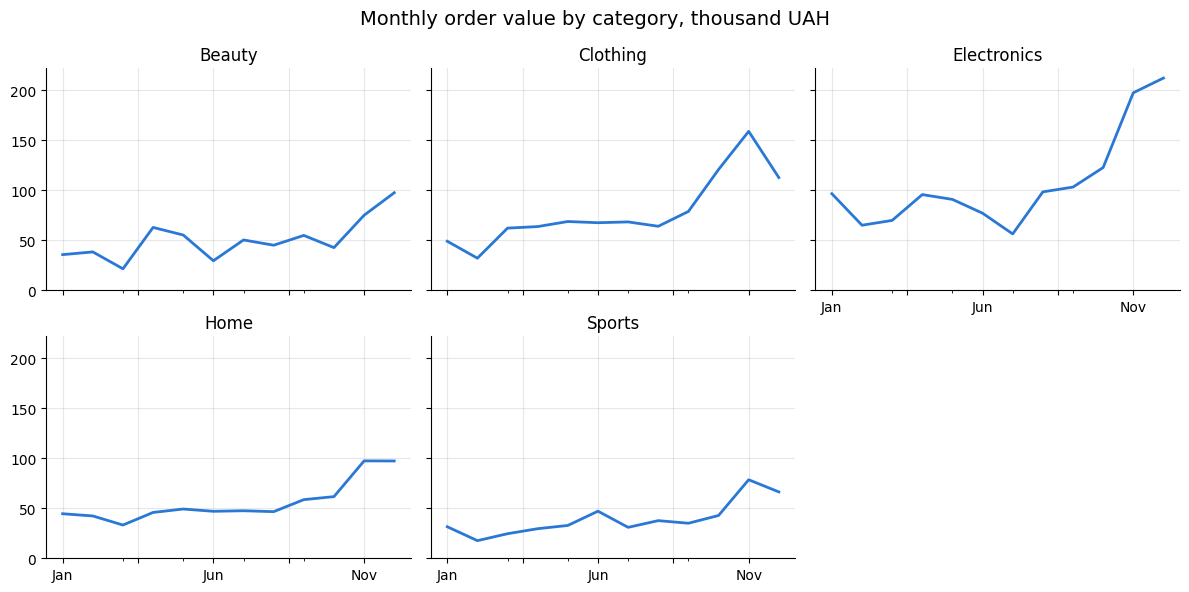

In [21]:
cat_month.plot(
    subplots=True, layout=(2, 3), figsize=(12, 6), sharey=True,
    title=list(cat_month.columns), legend=False, color="#2a78d6",
    xlabel="", ylim=(0, None),
)
plt.suptitle("Monthly order value by category, thousand UAH", fontsize=14)
plt.tight_layout()
plt.show()

Тепер добре видно: `Electronics` найбільше росте в кінці року, а `Clothing` має пік саме в листопаді.

💡 Усі графіки одного кольору, бо вони показують **одне й те саме** (суму замовлень), а категорію підписує заголовок. Різні кольори тут лише відволікали б.

### 📈 Теплова карта: день тижня × місяць
Коли купують найбільше? Зведемо кількість замовлень за днем тижня і місяцем і розфарбуємо таблицю (як у блокноті 4):

In [22]:
heat = pd.pivot_table(df, index="weekday", columns="month", values="order_id", aggfunc="count")
heat.index = heat.index.map(weekday_names)
heat.columns = heat.columns.map(month_names)

heat.style.background_gradient(cmap="Blues", axis=None)     # axis=None — одна шкала кольору для всієї таблиці

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
weekday,,,,,,,,,,,,
Mon,19,12,28,27,41,22,25,20,29,29,59,53
Tue,17,28,19,38,29,26,30,27,31,43,52,72
Wed,29,23,18,34,16,30,36,20,16,28,60,55
Thu,37,29,23,30,40,29,26,32,38,43,48,49
Fri,32,27,26,22,31,22,20,27,40,36,111,42
Sat,25,27,35,34,33,27,51,54,49,39,75,61
Sun,35,33,29,28,38,51,30,31,39,40,73,62


Найтемніша клітинка — п'ятниця листопада (Чорна п'ятниця). Далі йдуть майже всі дні листопада й грудня. Найсвітліші — будні першої половини року.

---
# ✍️ Практика

У таблиці `df` вже є дати та стовпці `month`, `quarter`, `weekday`, `delivery_days`, створені вище.

**Завдання 1.** Скільки замовлень було в кожному **кварталі**?

In [31]:
# Ваш код тут
df.groupby('quarter')['order_id'].count()

,order_id
quarter,
1,551
2,648
3,671
4,1130


**Завдання 2.** Чи впливає **час доставки** на **оцінку**? Порахуйте середню оцінку (`rating`) для кожного значення `delivery_days`.

In [33]:
# Ваш код тут
df.groupby('delivery_days')['rating'].mean()

,rating
delivery_days,
1.00,4.08
2.00,4.06
3.00,4.03
4.00,3.44
5.00,3.46


**Завдання 3.** Побудуйте графік суми замовлень по місяцях **лише для категорії `Clothing`**.

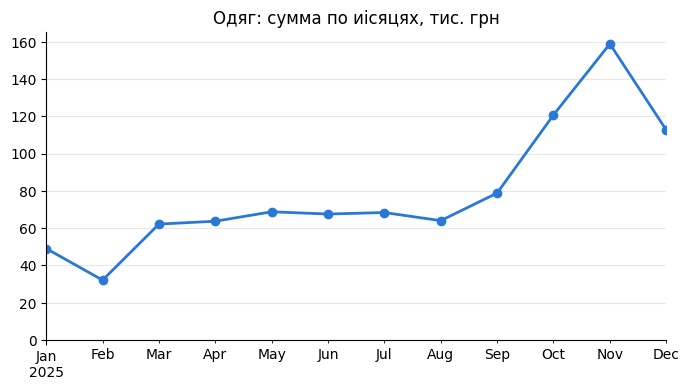

In [35]:
# Ваш код тут
clothes = df[df['category'] == 'Clothing']
clothes_monthly = clothes.groupby(clothes['order_date'].dt.to_period('M'))['revenue'].sum() / 1000
clothes_monthly.plot(marker='o')
plt.title('Одяг: сумма по иісяцях, тис. грн')
plt.xlabel('')
plt.ylim(bottom=0)
plt.show()

**Завдання 4.** Яка **середня сума** замовлення у вихідні (субота, неділя) і в будні?

In [37]:
# Ваш код ту
df['is_weekend'] = df['weekday'] >= 5
avg_by_weekend = df.groupby('is_weekend')['revenue'].mean().round(2)
avg_by_weekend.index = avg_by_weekend.index.map({False: "weekdays", True: "weekends"})
avg_by_weekend

,revenue
is_weekend,
weekdays,1 305.14
weekends,1 376.41


**Завдання 5 ⭐.** Для кожного клієнта знайдіть дату **першого** і **останнього** замовлення та скільки днів між ними. Покажіть 5 клієнтів з найдовшим «стажем» покупок.

In [46]:
# Ваш код тут
clients = df.groupby('customer_id').agg(
  first_order=('order_date', 'min'),
  last_order=('order_date', 'max'),
  count_orders=('order_id', 'count')
)
print(clients)
print()
clients['days_between'] = (clients['last_order'] - clients['first_order']).dt.days
clients.sort_values('days_between', ascending=False).head()

            first_order last_order  count_orders
customer_id                                     
C0001        2025-06-03 2025-11-28             3
C0002        2025-01-27 2025-12-11            11
C0003        2025-01-17 2025-12-28            12
C0004        2025-05-19 2025-12-26             4
C0005        2025-07-01 2025-12-27             3
...                 ...        ...           ...
C0396        2025-01-02 2025-12-23            19
C0397        2025-01-29 2025-12-19            13
C0398        2025-02-20 2025-12-27            15
C0399        2025-02-28 2025-12-29             2
C0400        2025-03-12 2025-03-12             1

[357 rows x 3 columns]



,first_order,last_order,count_orders,days_between
customer_id,,,,
C0219,2025-01-01,2025-12-31,17,364
C0026,2025-01-01,2025-12-30,32,363
C0216,2025-01-01,2025-12-29,27,362
C0161,2025-01-02,2025-12-30,24,362
C0294,2025-01-02,2025-12-28,24,360


**Завдання 6 📈.** Побудуйте на одному графіку **дві лінії**: сума замовлень по місяцях для каналів `Website` і `App`. Під кожною точкою підпишіть назву місяця (Jan, Feb, …).

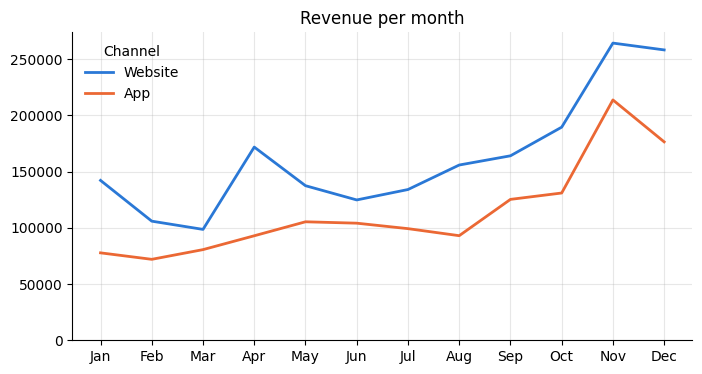

In [44]:
# Ваш код тут
orders_per_month = pd.pivot_table(df, index='month', columns='channel', values='revenue', aggfunc='sum')
orders_per_month = orders_per_month[['Website', 'App']]
orders_per_month.index = orders_per_month.index.map(month_names)

orders_per_month.plot()
plt.xticks(range(12), orders_per_month.index)
plt.title('Revenue per month')
plt.xlabel('')
plt.ylim(bottom=0)
plt.legend(title='Channel')
plt.show()

**Завдання 7 📈⭐.** Побудуйте графік **кількості замовлень по тижнях** (`resample("W", ...)`). Затініть листопад і підпишіть стрілкою найкращий тиждень.

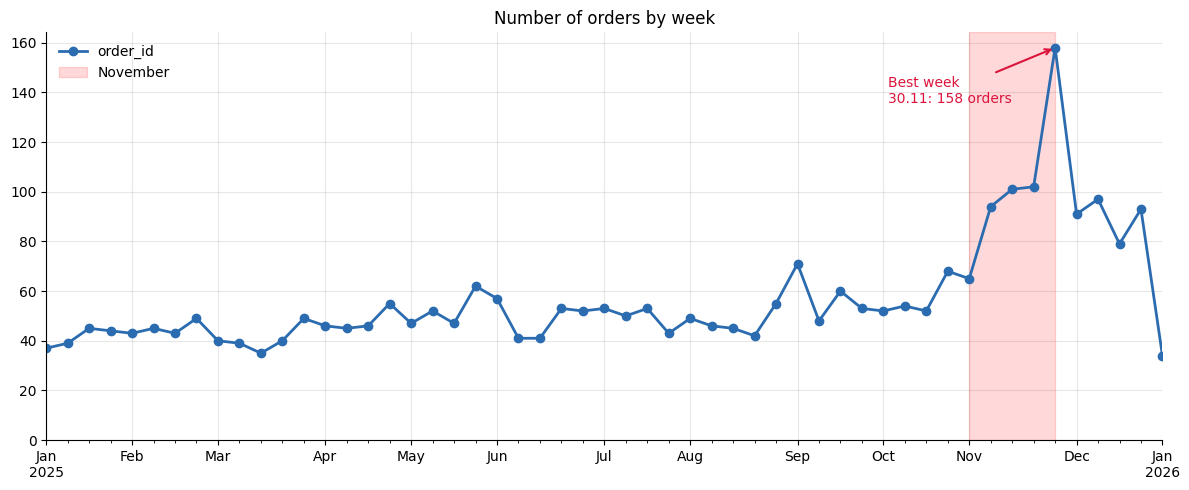

In [68]:
# Ваш код тут
weekly_orders = df.resample('W', on='order_date').count()['order_id']
#weekly_orders.plot()
fig, ax = plt.subplots(figsize=(12, 5))
weekly_orders.plot(ax=ax, marker='o', color='#2b6cb0')

ax.axvspan(pd.Timestamp('2025-11-01'), pd.Timestamp('2025-11-30'), color='red', alpha=0.15, label='November')

best_x, best_y = weekly_orders.idxmax(), weekly_orders.max()
ax.annotate(f'Best week \n{best_x:%d.%m}: {best_y} orders',
            xy=(best_x, best_y),
            xytext=(-120, -40), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5),
            fontsize=10, color='crimson')
ax.set_title('Number of orders by week')
ax.set_xlabel('')
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

---
# 📋 Шпаргалка блокнота 6

| Код | Що робить |
|---|---|
| `pd.to_datetime(df["col"])` | текст → дата |
| `pd.read_csv("f.csv", parse_dates=["col"])` | дати одразу під час читання |
| `.dt.year`, `.dt.month`, `.dt.day`, `.dt.quarter` | частини дати |
| `.dt.dayofweek` | день тижня (0 = Пн) |
| `.dt.to_period("M")` | рік-місяць (для групування) |
| `df[df["date"] >= "2025-06-01"]` | фільтр за датою |
| `df["date"].between("2025-11-01", "2025-11-30")` | фільтр за періодом |
| `(d2 - d1).dt.days` | різниця в днях |
| `df["date"] + pd.Timedelta(days=14)` | додати дні |
| `df.groupby(df["date"].dt.to_period("M"))["x"].sum()` | сума по місяцях |
| `df.resample("W", on="date")["x"].sum()` | сума по тижнях (`"D"`, `"W"`, `"MS"`, `"QS"`) |
| `series.pct_change()` | зміна до попереднього значення |
| `series.rolling(7).mean()` | ковзне середнє за 7 значень |
| `series.idxmax()` | підпис (дата) максимуму |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `s.index = s.index.map(month_names)` | номери місяців → назви |
| `plt.xticks(range(12), s.index)` | підпис під кожною точкою |
| `plt.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle="->"))` | стрілка з підписом |
| `plt.axvspan(початок, кінець, alpha=0.15)` | затінити період |
| `pivot.plot(marker="o")` | кілька ліній (стовпці таблиці) |
| `pivot.plot(subplots=True, layout=(2, 3), sharey=True, title=[...])` | малі мультиплікатори |
| `table.style.background_gradient(cmap="Blues", axis=None)` | теплова карта з однією шкалою |
| `plt.ylim(bottom=0)` | вісь Y від нуля |

---
### ➡️ Далі: блокнот 7 «Фінальний проєкт»
Збираємо все разом: робимо повний звіт для керівника, 📈 дашборд з чотирьох графіків на одній картинці, і зберігаємо все в Excel.

,order_id
quarter,
1,551
2,648
3,671
4,1130


,rating
delivery_days,
1.00,4.08
2.00,4.06
3.00,4.03
4.00,3.44
5.00,3.46


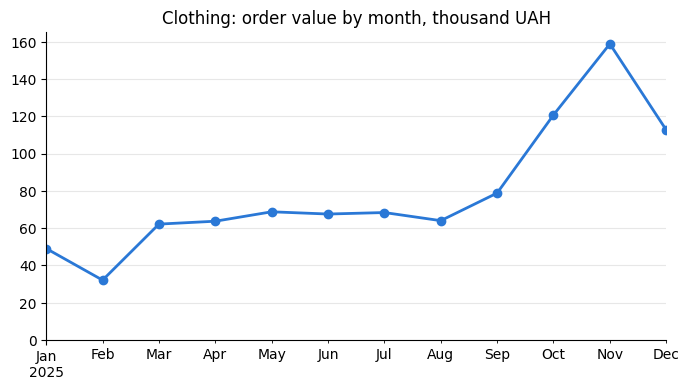

,revenue
is_weekend,
False,1 305.14
True,1 376.41


,first,last,orders,days_between
customer_id,,,,
C0219,2025-01-01,2025-12-31,17,364
C0026,2025-01-01,2025-12-30,32,363
C0216,2025-01-01,2025-12-29,27,362
C0161,2025-01-02,2025-12-30,24,362
C0294,2025-01-02,2025-12-28,24,360


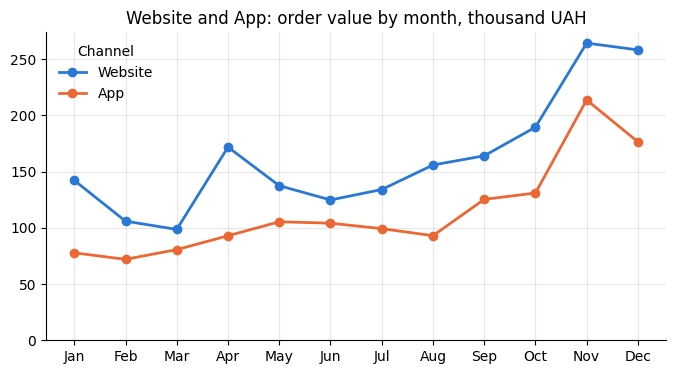

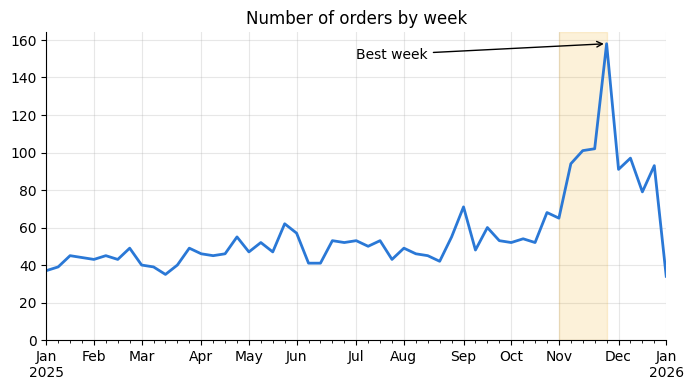

In [30]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ---------- Завдання 1 ----------
display(df.groupby("quarter")["order_id"].count())

# ---------- Завдання 2 ----------
display(df.groupby("delivery_days")["rating"].mean().round(2))
# Чим довше доставка, тим нижча оцінка: після 4+ днів очікування клієнти помітно менш задоволені.

# ---------- Завдання 3 ----------
clothes = df[df["category"] == "Clothing"]
clothes_monthly = clothes.groupby(clothes["order_date"].dt.to_period("M"))["revenue"].sum() / 1000

clothes_monthly.plot(marker="o")
plt.title("Clothing: order value by month, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

# ---------- Завдання 4 ----------
df["is_weekend"] = df["weekday"] >= 5
display(df.groupby("is_weekend")["revenue"].mean().round(2))
# True — вихідні, False — будні.

# ---------- Завдання 5 ⭐ ----------
clients = df.groupby("customer_id").agg(
    first=("order_date", "min"),
    last=("order_date", "max"),
    orders=("order_id", "count"),
)
clients["days_between"] = (clients["last"] - clients["first"]).dt.days

display(clients.sort_values("days_between", ascending=False).head())

# ---------- Завдання 6 📈 ----------
ch_month = pd.pivot_table(df, index="month", columns="channel", values="revenue", aggfunc="sum") / 1000
ch_month = ch_month[["Website", "App"]]
ch_month.index = ch_month.index.map(month_names)

ch_month.plot(marker="o")
plt.xticks(range(12), ch_month.index)
plt.title("Website and App: order value by month, thousand UAH")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend(title="Channel")
plt.show()

# ---------- Завдання 7 📈⭐ ----------
weekly_orders = df.resample("W", on="order_date")["order_id"].count()

weekly_orders.plot()
best_week = weekly_orders.idxmax()
plt.annotate(
    "Best week",
    xy=(best_week, weekly_orders.max()),
    xytext=(best_week - pd.Timedelta(days=150), weekly_orders.max() * 0.95),
    arrowprops=dict(arrowstyle="->"),
)
plt.axvspan(pd.Timestamp("2025-11-01"), pd.Timestamp("2025-11-30"), color="#eda100", alpha=0.15)
plt.title("Number of orders by week")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()
